# 📊 1. Data Understanding & Preparation - Analyse Exploratoire et Préparation

## Objectif
Comprendre la structure et les caractéristiques du dataset sur les dépenses de la Génération Z, puis nettoyer et préparer les données pour l'analyse et la modélisation.

## Plan d'analyse et préparation
1. Importation des bibliothèques
2. Chargement des données
3. Analyse de la structure du dataset
4. Statistiques descriptives
5. Détection des valeurs manquantes
6. Analyse préliminaire des outliers
7. Visualisations exploratoires
8. Analyse des corrélations
9. **Traitement des outliers** (limitation)
10. Vérification de la qualité des données
11. Sauvegarde des données nettoyées


In [1]:
# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy import stats
from scipy.stats import normaltest
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
import os
import json
import sys
sys.path.insert(0, '..')  # utils_outliers.py est à la racine du projet
from utils_outliers import cap_outliers_iqr, get_outlier_summary

warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# Configuration pour l'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

# Création des dossiers nécessaires
os.makedirs('../data/processed', exist_ok=True)
os.makedirs('../data/results', exist_ok=True)

print("📚 Bibliothèques importées avec succès!")


📚 Bibliothèques importées avec succès!


## 1. Chargement des données


In [2]:
# Chargement du dataset brut
df = pd.read_csv('../data/raw/dataset_genz_6000.csv', sep=';')

print(f"✅ Données chargées avec succès!")
print(f"📊 Dimensions: {df.shape[0]} lignes × {df.shape[1]} colonnes")
print(f"\n🔍 Aperçu des premières lignes:")
df.head()


✅ Données chargées avec succès!
📊 Dimensions: 6000 lignes × 15 colonnes

🔍 Aperçu des premières lignes:


,ID,Age,Income (USD),Rent (USD),Groceries (USD),Eating Out (USD),Entertainment (USD),Subscription Services (USD),Education (USD),Online Shopping (USD),Savings (USD),Investments (USD),Travel (USD),Fitness (USD),Miscellaneous (USD)
0,1,22,1824.38,749.70,223.34,190.42,73.55,64.11,374.44,207.76,-296.73,0.00,18.11,2.25,58.09
1,2,22,2275.27,854.25,242.91,184.83,177.46,45.60,436.52,218.97,-79.58,19.39,12.23,9.14,145.08
2,3,27,5353.69,1619.29,441.90,418.95,419.27,134.25,136.50,469.73,482.19,720.49,269.55,154.25,292.60
3,4,20,2617.21,560.51,265.13,218.83,97.26,47.49,652.39,209.58,205.88,23.31,58.27,7.46,133.76
4,5,22,5045.46,967.80,166.47,84.18,106.62,31.28,12.46,108.39,1055.57,566.56,33.79,55.78,1900.67


## 2. Analyse de la structure du dataset


In [3]:
# Informations générales sur le dataset
print("📋 Informations sur le dataset:")
print("=" * 50)
print(f"Nombre de lignes: {df.shape[0]}")
print(f"Nombre de colonnes: {df.shape[1]}")
print(f"\n📝 Types de données:")
print(df.dtypes)
print(f"\n📊 Résumé des données:")
df.info()

# Identification des colonnes numériques (exclure ID)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols_for_outliers = [col for col in numeric_cols if col != 'ID']

print(f"\n📊 Colonnes numériques identifiées: {len(numeric_cols_for_outliers)} variables")


📋 Informations sur le dataset:
Nombre de lignes: 6000
Nombre de colonnes: 15

📝 Types de données:
ID                               int64
Age                              int64
Income (USD)                   float64
Rent (USD)                     float64
Groceries (USD)                float64
Eating Out (USD)               float64
Entertainment (USD)            float64
Subscription Services (USD)    float64
Education (USD)                float64
Online Shopping (USD)          float64
Savings (USD)                  float64
Investments (USD)              float64
Travel (USD)                   float64
Fitness (USD)                  float64
Miscellaneous (USD)            float64
dtype: object

📊 Résumé des données:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           6000 non-null   int64  

## 3. Statistiques descriptives


In [4]:
# Statistiques descriptives pour les variables numériques
print("📈 Statistiques descriptives (AVANT nettoyage):")
print("=" * 50)
df[numeric_cols].describe()


📈 Statistiques descriptives (AVANT nettoyage):


,ID,Age,Income (USD),Rent (USD),Groceries (USD),Eating Out (USD),Entertainment (USD),Subscription Services (USD),Education (USD),Online Shopping (USD),Savings (USD),Investments (USD),Travel (USD),Fitness (USD),Miscellaneous (USD)
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,3000.500000,23.176000,4284.505415,1167.654058,331.018073,357.229822,259.768690,85.856342,237.346488,295.137427,677.407420,318.557360,262.939275,88.528613,296.628537
std,1732.195139,2.572831,1666.724518,566.954573,109.260735,202.834492,158.142371,38.475326,210.855989,150.581405,1107.885259,290.688548,214.935809,63.207541,383.018929
min,1.000000,18.000000,1000.020000,400.070000,150.140000,50.110000,50.140000,20.090000,0.020000,50.290000,-3354.130000,0.000000,0.020000,0.010000,0.000000
25%,1500.750000,21.000000,2883.710000,700.510000,248.055000,185.025000,129.480000,56.107500,81.092500,171.910000,-124.215000,8.387500,77.220000,37.387500,119.955000
50%,3000.500000,24.000000,4388.015000,995.105000,318.070000,327.400000,232.640000,76.240000,148.590000,267.185000,697.940000,288.845000,221.600000,77.145000,183.860000
75%,4500.250000,25.000000,5606.430000,1539.037500,396.450000,488.717500,363.235000,115.817500,355.542500,414.152500,1448.747500,515.645000,392.402500,130.885000,271.092500
max,6000.000000,27.000000,8141.770000,2499.610000,599.940000,999.390000,799.290000,199.850000,799.910000,699.390000,4138.430000,999.680000,997.420000,299.810000,2939.790000


## 4. Détection des valeurs manquantes


In [5]:
# Analyse des valeurs manquantes
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing_Count': missing_data,
    'Missing_Percentage': missing_percent
})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)

if len(missing_df) > 0:
    print("⚠️ Valeurs manquantes détectées:")
    print(missing_df)
else:
    print("✅ Aucune valeur manquante détectée!")


✅ Aucune valeur manquante détectée!


## 5. Analyse préliminaire des outliers


In [6]:
# Analyse préliminaire des outliers (AVANT traitement)
print("🔍 Analyse préliminaire des outliers (méthode IQR):")
print("=" * 60)
outlier_summary_before = get_outlier_summary(df, numeric_cols_for_outliers, method='iqr', factor=1.5)
print(outlier_summary_before)

# Résumé
total_outliers_before = outlier_summary_before['Outliers_Count'].sum()
print(f"\n📊 Résumé:")
print(f"   Total d'outliers détectés: {total_outliers_before}")
print(f"   Colonnes avec outliers: {(outlier_summary_before['Outliers_Count'] > 0).sum()} sur {len(outlier_summary_before)}")


🔍 Analyse préliminaire des outliers (méthode IQR):
                         Column  Outliers_Count  Outliers_Percentage  \
0                           Age               0             0.000000   
1                  Income (USD)               0             0.000000   
2                    Rent (USD)               0             0.000000   
3               Groceries (USD)               0             0.000000   
4              Eating Out (USD)              49             0.816667   
5           Entertainment (USD)             109             1.816667   
6   Subscription Services (USD)               0             0.000000   
7               Education (USD)              88             1.466667   
8         Online Shopping (USD)               0             0.000000   
9                 Savings (USD)               7             0.116667   
10            Investments (USD)               0             0.000000   
11                 Travel (USD)             108             1.800000   
12           

## 6. Visualisations exploratoires


In [7]:
# Distribution de l'âge
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['Age'], bins=20, edgecolor='black', alpha=0.7)
plt.title('Distribution de l\'âge', fontsize=14, fontweight='bold')
plt.xlabel('Âge')
plt.ylabel('Fréquence')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.boxplot(df['Age'])
plt.title('Boxplot de l\'âge', fontsize=14, fontweight='bold')
plt.ylabel('Âge')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../data/results/age_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"📊 Statistiques de l'âge:")
print(f"   Moyenne: {df['Age'].mean():.2f} ans")
print(f"   Médiane: {df['Age'].median():.2f} ans")
print(f"   Écart-type: {df['Age'].std():.2f} ans")


<Figure size 1200x500 with 2 Axes>

📊 Statistiques de l'âge:
   Moyenne: 23.18 ans
   Médiane: 24.00 ans
   Écart-type: 2.57 ans


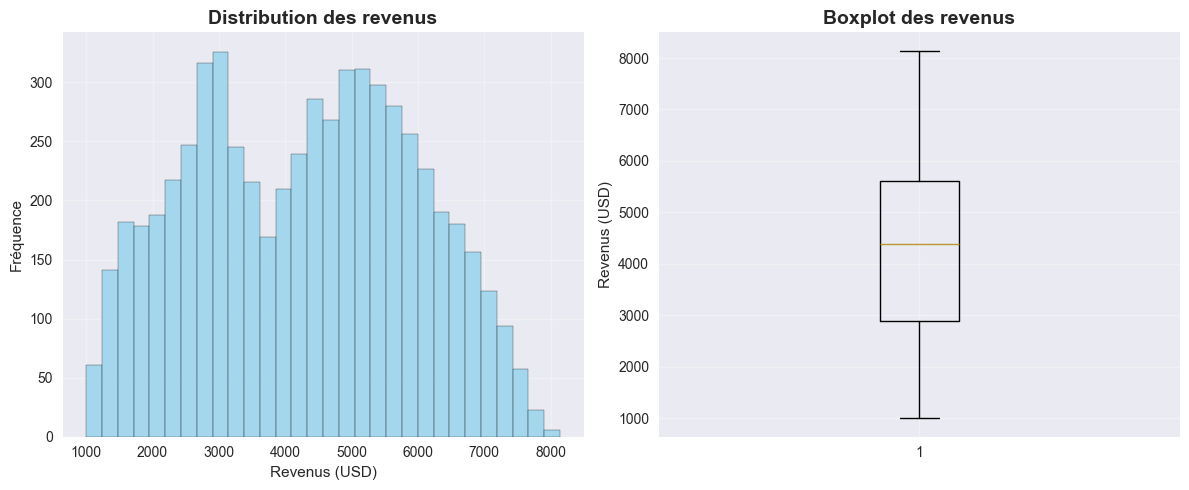

📊 Statistiques des revenus:
   Moyenne: $4,284.51
   Médiane: $4,388.01
   Écart-type: $1,666.72


In [8]:
# Distribution des revenus
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['Income (USD)'], bins=30, edgecolor='black', alpha=0.7, color='skyblue')
plt.title('Distribution des revenus', fontsize=14, fontweight='bold')
plt.xlabel('Revenus (USD)')
plt.ylabel('Fréquence')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.boxplot(df['Income (USD)'])
plt.title('Boxplot des revenus', fontsize=14, fontweight='bold')
plt.ylabel('Revenus (USD)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../data/results/income_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"📊 Statistiques des revenus:")
print(f"   Moyenne: ${df['Income (USD)'].mean():,.2f}")
print(f"   Médiane: ${df['Income (USD)'].median():,.2f}")
print(f"   Écart-type: ${df['Income (USD)'].std():,.2f}")


## 7. Analyse des corrélations


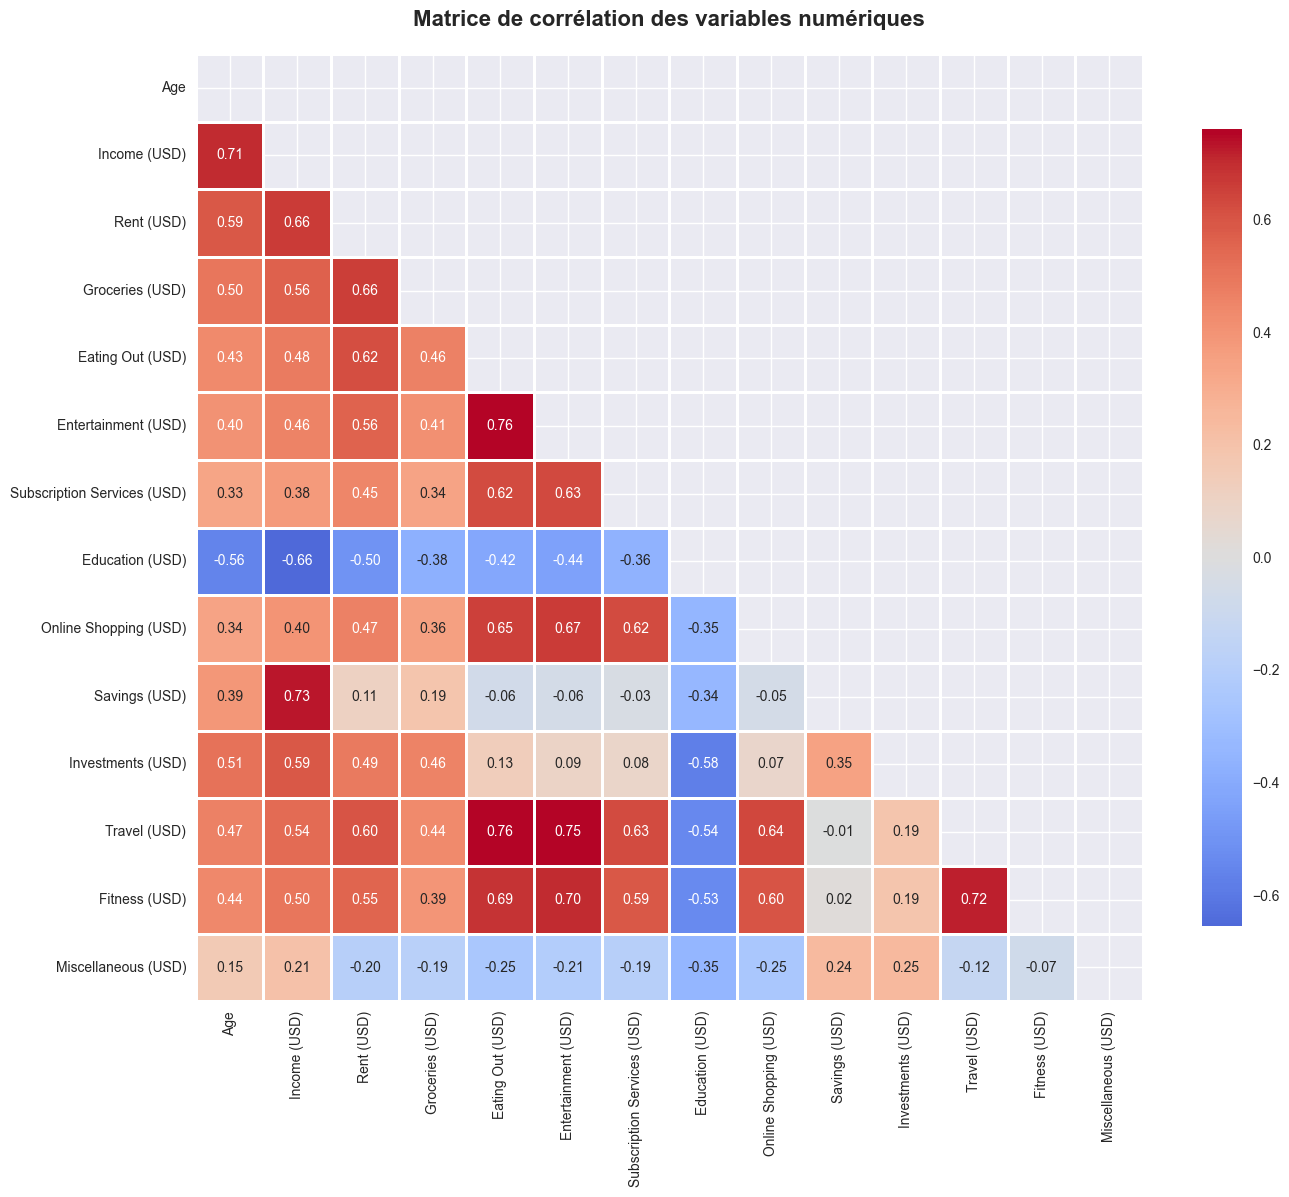


🔗 Corrélations les plus fortes (hors diagonale):
             Variable 1             Variable 2  Corrélation
52     Eating Out (USD)           Travel (USD)     0.761135
46     Eating Out (USD)    Entertainment (USD)     0.756730
60  Entertainment (USD)           Travel (USD)     0.754156
20         Income (USD)          Savings (USD)     0.730774
88         Travel (USD)          Fitness (USD)     0.717925
0                   Age           Income (USD)     0.705533
61  Entertainment (USD)          Fitness (USD)     0.703820
53     Eating Out (USD)          Fitness (USD)     0.689166
57  Entertainment (USD)  Online Shopping (USD)     0.666056
13         Income (USD)             Rent (USD)     0.664208


In [9]:
# Matrice de corrélation
correlation_matrix = df[numeric_cols_for_outliers].corr()

# Visualisation de la matrice de corrélation
plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Matrice de corrélation des variables numériques', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('../data/results/correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# Corrélations les plus fortes
print("\n🔗 Corrélations les plus fortes (hors diagonale):")
corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        corr_pairs.append({
            'Variable 1': correlation_matrix.columns[i],
            'Variable 2': correlation_matrix.columns[j],
            'Corrélation': correlation_matrix.iloc[i, j]
        })

corr_df = pd.DataFrame(corr_pairs)
corr_df['Abs_Correlation'] = corr_df['Corrélation'].abs()
print(corr_df.nlargest(10, 'Abs_Correlation')[['Variable 1', 'Variable 2', 'Corrélation']])


## 8. Traitement des outliers

**Important**: Nous utilisons le module `utils_outliers.py` pour éviter la redondance de code.
Nous choisissons de limiter (cap) les outliers plutôt que de les supprimer pour préserver la taille de l'échantillon.


In [10]:
# Traitement des outliers par limitation (winsorization)
# Cette méthode préserve tous les échantillons en limitant les valeurs extrêmes
df_cleaned = cap_outliers_iqr(df, numeric_cols_for_outliers, factor=1.5, inplace=False)

print(f"✅ Outliers traités (limitation avec IQR factor=1.5)")
print(f"📊 Dimensions après traitement: {df_cleaned.shape[0]} lignes × {df_cleaned.shape[1]} colonnes")
print(f"   (Aucune ligne supprimée - valeurs limitées)")

# Vérification après traitement
print("\n🔍 Analyse des outliers APRÈS traitement:")
print("=" * 60)
outlier_summary_after = get_outlier_summary(df_cleaned, numeric_cols_for_outliers, method='iqr', factor=1.5)
print(outlier_summary_after)

# Comparaison avant/après
total_outliers_after = outlier_summary_after['Outliers_Count'].sum()
print(f"\n📊 Comparaison:")
print(f"   Outliers avant traitement: {total_outliers_before}")
print(f"   Outliers après traitement: {total_outliers_after}")
print(f"   Réduction: {total_outliers_before - total_outliers_after} outliers")


✅ Outliers traités (limitation avec IQR factor=1.5)
📊 Dimensions après traitement: 6000 lignes × 15 colonnes
   (Aucune ligne supprimée - valeurs limitées)

🔍 Analyse des outliers APRÈS traitement:
                         Column  Outliers_Count  Outliers_Percentage  \
0                           Age               0                  0.0   
1                  Income (USD)               0                  0.0   
2                    Rent (USD)               0                  0.0   
3               Groceries (USD)               0                  0.0   
4              Eating Out (USD)               0                  0.0   
5           Entertainment (USD)               0                  0.0   
6   Subscription Services (USD)               0                  0.0   
7               Education (USD)               0                  0.0   
8         Online Shopping (USD)               0                  0.0   
9                 Savings (USD)               0                  0.0   
10        

## 8.5. Note sur la Normalisation/Standardisation

**Important**: Nous ne normalisons pas encore ici car cela sera fait dans les notebooks de modélisation selon les besoins spécifiques de chaque algorithme.

**Raisons**:
- ✅ **Feature Engineering** : Nous gardons les données brutes pour créer de nouvelles features (ratios, indices, etc.)
- ✅ **Flexibilité** : Chaque algorithme de modélisation nécessite une approche différente :
  - **SVM** : Nécessite la standardisation (basé sur les distances)
  - **Régression** : Nécessite la standardisation pour certains modèles
  - **Arbres de décision (Decision Tree, Random Forest, XGBoost)** : N'ont **PAS** besoin de standardisation
- ✅ **Bonnes pratiques** : La standardisation doit être faite après le Feature Engineering et seulement pour les algorithmes qui en ont besoin

**Conclusion** : Les données nettoyées sont prêtes pour le Feature Engineering. La standardisation sera appliquée dans les notebooks de modélisation appropriés.


## 9. Vérification de la qualité des données


In [11]:
# Vérification des valeurs manquantes après traitement
missing_data_after = df_cleaned.isnull().sum()
if missing_data_after.sum() > 0:
    print("⚠️ Valeurs manquantes détectées après traitement:")
    print(missing_data_after[missing_data_after > 0])
    # Imputation si nécessaire
    imputer = SimpleImputer(strategy='median')
    df_cleaned[numeric_cols_for_outliers] = imputer.fit_transform(df_cleaned[numeric_cols_for_outliers])
    print("✅ Valeurs manquantes imputées avec la médiane")
else:
    print("✅ Aucune valeur manquante détectée après traitement!")

# Vérification des valeurs négatives (incohérences)
negative_cols = []
for col in numeric_cols_for_outliers:
    if (df_cleaned[col] < 0).any():
        negative_cols.append(col)

if negative_cols:
    print(f"\n⚠️ Colonnes avec valeurs négatives: {negative_cols}")
    # Les valeurs négatives pour les dépenses/revenus sont incohérentes, on les remplace par 0
    for col in negative_cols:
        df_cleaned[col] = df_cleaned[col].clip(lower=0)
    print("✅ Valeurs négatives corrigées (remplacées par 0)")
else:
    print("\n✅ Aucune valeur négative incohérente détectée!")

# Statistiques après nettoyage
print("\n📊 Statistiques après nettoyage:")
print("=" * 60)
print(df_cleaned[numeric_cols_for_outliers].describe())


✅ Aucune valeur manquante détectée après traitement!

⚠️ Colonnes avec valeurs négatives: ['Savings (USD)']
✅ Valeurs négatives corrigées (remplacées par 0)

📊 Statistiques après nettoyage:


               Age  Income (USD)   Rent (USD)  Groceries (USD)  \
count  6000.000000   6000.000000  6000.000000      6000.000000   
mean     23.176000   4284.505415  1167.654058       331.018073   
std       2.572831   1666.724518   566.954573       109.260735   
min      18.000000   1000.020000   400.070000       150.140000   
25%      21.000000   2883.710000   700.510000       248.055000   
50%      24.000000   4388.015000   995.105000       318.070000   
75%      25.000000   5606.430000  1539.037500       396.450000   
max      27.000000   8141.770000  2499.610000       599.940000   

       Eating Out (USD)  Entertainment (USD)  Subscription Services (USD)  \
count       6000.000000          6000.000000                  6000.000000   
mean         356.982254           259.012833                    85.856342   
std          202.091660           155.816112                    38.475326   
min           50.110000            50.140000                    20.090000   
25%          185.025

## 10. Sauvegarde des données et résultats


In [12]:
# Sauvegarde des données nettoyées
df_cleaned.to_csv('../data/processed/dataset_cleaned.csv', index=False)

# Sauvegarde des résultats de l'analyse exploratoire
exploratory_summary = {
    'dataset_shape': df.shape,
    'dataset_shape_after_cleaning': df_cleaned.shape,
    'numeric_columns': numeric_cols,
    'missing_values': missing_data.to_dict(),
    'age_stats': {
        'mean': float(df['Age'].mean()),
        'median': float(df['Age'].median()),
        'std': float(df['Age'].std())
    },
    'income_stats': {
        'mean': float(df['Income (USD)'].mean()),
        'median': float(df['Income (USD)'].median()),
        'std': float(df['Income (USD)'].std())
    },
    'outlier_summary_before': outlier_summary_before.to_dict('records'),
    'outlier_summary_after': outlier_summary_after.to_dict('records'),
    'outlier_treatment': 'IQR capping (factor=1.5)',
    'total_outliers_before': int(total_outliers_before),
    'total_outliers_after': int(total_outliers_after)
}

with open('../data/results/exploratory_analysis_summary.json', 'w', encoding='utf-8') as f:
    json.dump(exploratory_summary, f, indent=2, ensure_ascii=False)

# Sauvegarde des informations de normalisation
normalization_info = {
    'outlier_treatment': 'IQR capping (factor=1.5)',
    'outlier_summary_before': outlier_summary_before.to_dict('records'),
    'outlier_summary_after': outlier_summary_after.to_dict('records'),
    'numeric_columns': numeric_cols_for_outliers,
    'dataset_shape_after_cleaning': df_cleaned.shape
}

with open('../data/results/normalization_info.json', 'w', encoding='utf-8') as f:
    json.dump(normalization_info, f, indent=2, ensure_ascii=False)

print("✅ Données et résultats sauvegardés!")
print(f"📁 Données nettoyées: data/processed/dataset_cleaned.csv")
print(f"📁 Résultats exploratoires: data/results/exploratory_analysis_summary.json")
print(f"📁 Métadonnées: data/results/normalization_info.json")
print(f"\n📊 Résumé final:")
print(f"   - Lignes: {df_cleaned.shape[0]}")
print(f"   - Colonnes: {df_cleaned.shape[1]}")
print(f"   - Outliers traités par limitation (winsorization)")
print(f"   - Données prêtes pour le Feature Engineering")


✅ Données et résultats sauvegardés!
📁 Données nettoyées: data/processed/dataset_cleaned.csv
📁 Résultats exploratoires: data/results/exploratory_analysis_summary.json
📁 Métadonnées: data/results/normalization_info.json

📊 Résumé final:
   - Lignes: 6000
   - Colonnes: 15
   - Outliers traités par limitation (winsorization)
   - Données prêtes pour le Feature Engineering
